Dataset shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-

/tmp/ipykernel_5723/3004155375.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn", palette=["#2ecc71", "#e74c3c"])


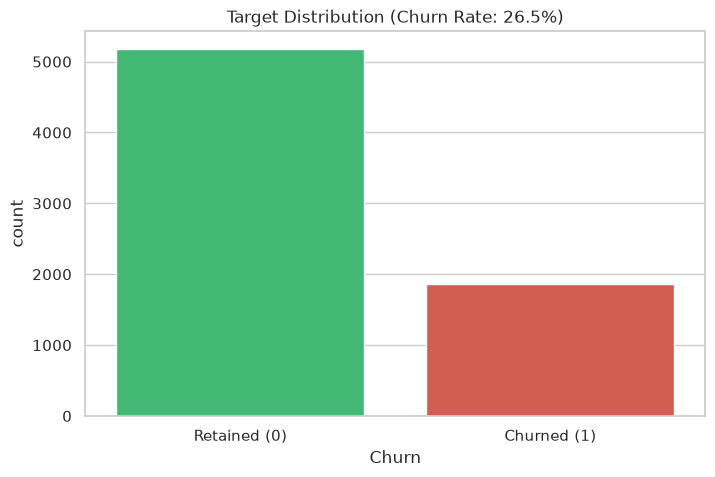

         Contract  ChurnRate%
0  Month-to-month   42.709677
1        One year   11.269518
2        Two year    2.831858


/tmp/ipykernel_5723/3004155375.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=contract_churn, x="Contract", y="ChurnRate%", palette="Blues_d")


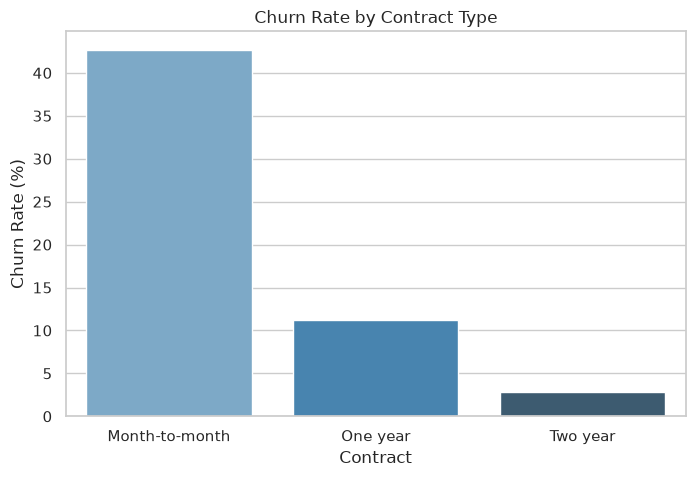

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Load raw dataset
df = pd.read_csv("../../data/raw/telco_churn.csv")

print(f"Dataset shape: {df.shape}")
df.info()

# Check how many values in TotalCharges are blank spaces
empty_total_charges = df[df["TotalCharges"].str.strip() == ""]
print(f"Rows with blank TotalCharges: {len(empty_total_charges)}")
print(empty_total_charges[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

# Coerce invalid parsing to NaN, then fill tenure=0 rows with 0.0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

# Verify no nulls remain
print(f"Missing values in TotalCharges after fix: {df['TotalCharges'].isnull().sum()}")

# Map target to binary integer
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

churn_counts = df["Churn"].value_counts()
churn_rate = df["Churn"].mean() * 100

print(f"Non-Churn (0): {churn_counts[0]}")
print(f"Churn (1):     {churn_counts[1]}")
print(f"Overall Churn Rate: {churn_rate:.2f}%")

# Visualize target distribution
sns.countplot(data=df, x="Churn", palette=["#2ecc71", "#e74c3c"])
plt.title(f"Target Distribution (Churn Rate: {churn_rate:.1f}%)")
plt.xticks([0, 1], ["Retained (0)", "Churned (1)"])
plt.show()

contract_churn = df.groupby("Contract")["Churn"].mean().reset_index()
contract_churn["ChurnRate%"] = contract_churn["Churn"] * 100

print(contract_churn[["Contract", "ChurnRate%"]])

sns.barplot(data=contract_churn, x="Contract", y="ChurnRate%", palette="Blues_d")
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate (%)")
plt.show()

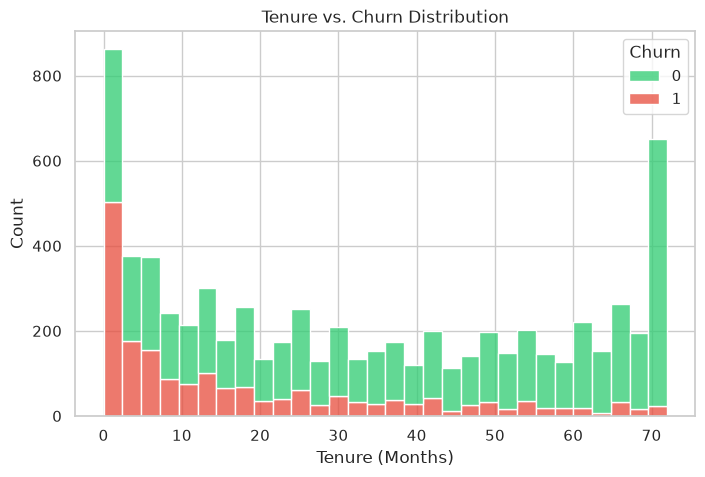

In [7]:
sns.histplot(data=df, x="tenure", hue="Churn", multiple="stack", bins=30, palette=["#2ecc71", "#e74c3c"])
plt.title("Tenure vs. Churn Distribution")
plt.xlabel("Tenure (Months)")
plt.show()

In [8]:
tech_support_churn = df.groupby(["InternetService", "TechSupport"])["Churn"].mean().unstack() * 100
print(tech_support_churn)

TechSupport             No  No internet service        Yes
InternetService                                           
DSL              27.755430                  NaN   9.677419
Fiber optic      49.372197                  NaN  22.632794
No                     NaN              7.40498        NaN


In [11]:
from pathlib import Path

# Drop customerID since it has zero predictive power and causes noise
clean_df = df.drop(columns=["customerID"])

# Save cleaned dataframe
output_path = Path("../../data/processed")
output_path.mkdir(parents=True, exist_ok=True)
clean_df.to_csv(output_path / "telco_cleaned.csv", index=False)
print(f"Saved cleaned data to data/processed/telco_cleaned.csv: {clean_df.shape}")

Saved cleaned data to data/processed/telco_cleaned.csv: (7043, 20)
